# 04: A Conventional Baseline

**The question here: can you predict who finishes on the podium, and what does answering that tell you which the first three notebooks did not?**

Notebooks 01 to 03 asked how much of a Formula 1 result comes from the driver and how much from the car, and built a model to take those two apart. This notebook does the ordinary thing instead: gradient boosting, the tool most data scientists reach for first, on one yes-or-no question. Does this driver finish in the top three? Gradient boosting grows many small decision trees, each correcting the mistakes of the ones before it.

**As a contrast.** A model built to predict results has no reason to separate Verstappen from his Red Bull. It learns that cars starting at the front finish at the front, which is all it needs to score well. Set beside the decomposition, it shows what the harder approach buys.

**As a competency check.** Building features, testing whether they help, handling an outcome that only happens 15% of the time, and comparing model families are the routine work of applied machine learning. The decomposition uses none of it.

**The rule, fixed before anything is fitted.** Every choice gets made on the 2021, 2022 and 2023 seasons. 2024 and 2025 are scored once, at the end, and whatever they say, the choice already made stands. No search over model settings and no combining several models together, because this is not the centrepiece of the project. Where that limits a conclusion, the conclusion says so.

## Where the race results come from

**The earlier notebooks measured qualifying pace from lap times. Predicting a race result needs different data: who started where, who finished where, and how many points they scored.**

[TracingInsights/RaceData](https://github.com/TracingInsights/RaceData) mirrors the Ergast/F1DB dataset: 20 tables covering every world championship race from 1950 on, under CC0. Four matter here: `races` (one row per grand prix), `results` (one row per car entered), `drivers` and `constructors`.

In [1]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

archive = requests.get(
    'https://raw.githubusercontent.com/TracingInsights/RaceData/main/data.zip', timeout=60
)
with zipfile.ZipFile(io.BytesIO(archive.content)) as z:
    tables = {name: pd.read_csv(z.open(f'{name}.csv'))
              for name in ['races', 'results', 'sprint_results',
                           'drivers', 'constructors']}

for name, table in tables.items():
    print(f'{name:14s} {table.shape}')

races          (1171, 18)
results        (27480, 18)
sprint_results (568, 17)
drivers        (865, 9)
constructors   (214, 5)


In [2]:
races = tables['races'][tables['races']['year'].between(2018, 2025)]

race_results = (
    tables['results']
    .merge(races[['raceId', 'year', 'round', 'name', 'date']], on='raceId')
    .merge(tables['drivers'][['driverId', 'code']], on='driverId')
    .merge(tables['constructors'][['constructorId', 'name']].rename(
        columns={'name': 'constructor'}), on='constructorId')
)

# points come from two tables: sprint points are recorded separately and a
# championship total that leaves them out is not a championship total
sprint_points = (tables['sprint_results'].groupby(['raceId', 'driverId'])['points']
                 .sum().rename('sprint_points'))
race_results = race_results.merge(sprint_points, on=['raceId', 'driverId'], how='left')
race_results['sprint_points'] = race_results['sprint_points'].fillna(0)

print('rows:', len(race_results))
print('sprint points awarded per season:',
      race_results.groupby('year')['sprint_points'].sum().to_dict())
print('races:', race_results['raceId'].nunique())
print('seasons:', sorted(race_results['year'].unique()))
race_results[['year', 'round', 'name', 'code', 'constructor',
              'grid', 'position', 'positionText', 'positionOrder', 'points']].head()

rows: 3458
sprint points awarded per season: {2018: 0.0, 2019: 0.0, 2020: 0.0, 2021: 18.0, 2022: 108.0, 2023: 216.0, 2024: 216.0, 2025: 216.0}
races: 173
seasons: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,year,round,name,code,constructor,grid,position,positionText,positionOrder,points
0,2018,1,Australian Grand Prix,VET,Ferrari,3,1,1,1,25.0
1,2018,1,Australian Grand Prix,HAM,Mercedes,1,2,2,2,18.0
2,2018,1,Australian Grand Prix,RAI,Ferrari,2,3,3,3,15.0
3,2018,1,Australian Grand Prix,RIC,Red Bull,8,4,4,4,12.0
4,2018,1,Australian Grand Prix,ALO,McLaren,10,5,5,5,10.0


## What the result fields actually mean

**Two columns decide this whole exercise, and both contain values that are not what they look like.**

`positionOrder` ranks every entry, including cars that never reached the flag. A driver whose engine failed on lap 3 still gets a number, placed behind everyone who finished, so sorting on it alone would treat a retirement as a real result. `positionText` tells the two apart: a number means the driver was classified in that place, `R` means they retired.

`grid` should say which slot a car started from. Mostly it does, but it also carries codes for cars that did not take a normal start, so it cannot be turned into a number until those are dealt with.

In [3]:
print('positionText values:')
print(race_results['positionText'].value_counts().head(12))
print()
print('grid values that are not a starting slot:')
print(race_results.loc[~race_results['grid'].astype(str).str.isdigit()
                       | (race_results['grid'].astype(str) == '0'),
                       'grid'].value_counts())

positionText values:
positionText
R     425
2     173
1     173
4     173
5     173
6     173
3     173
7     173
8     173
10    173
9     173
12    173
Name: count, dtype: int64

grid values that are not a starting slot:
grid
0     70
\N    20
Name: count, dtype: int64


**Each classified finishing position shown appears exactly 173 times, once per race**, and the counts fall away further down the column as cars retire. Retirements are the largest single value at 425. None need separate handling: a podium requires the literal value `1`, `2` or `3`, so a letter can never satisfy it.

**The `grid` column holds two values that are not starting slots.** 70 rows contain `0`, this dataset's code for a car that started from the pit lane. 20 rows contain `\N`, the marker for a missing value. The next cell checks what they are, which decides how to handle them.

In [4]:
missing_grid = race_results[race_results['grid'].astype(str) == '\\N']
print('rows with no grid position:', len(missing_grid))
print(missing_grid[['year', 'name', 'code', 'constructor',
                    'positionText', 'laps', 'points']].head(10).to_string(index=False))
print()
print('laps completed by these entries:', sorted(missing_grid['laps'].unique()))

rows with no grid position: 20
 year             name code  constructor positionText  laps  points
 2025 Qatar Grand Prix  VER     Red Bull            1    57    25.0
 2025 Qatar Grand Prix  PIA      McLaren            2    57    18.0
 2025 Qatar Grand Prix  SAI     Williams            3    57    15.0
 2025 Qatar Grand Prix  NOR      McLaren            4    57    12.0
 2025 Qatar Grand Prix  ANT     Mercedes            5    57    10.0
 2025 Qatar Grand Prix  RUS     Mercedes            6    57     8.0
 2025 Qatar Grand Prix  ALO Aston Martin            7    57     6.0
 2025 Qatar Grand Prix  LEC      Ferrari            8    57     4.0
 2025 Qatar Grand Prix  LAW   RB F1 Team            9    57     2.0
 2025 Qatar Grand Prix  TSU     Red Bull           10    57     1.0

laps completed by these entries: [np.int64(6), np.int64(41), np.int64(55), np.int64(56), np.int64(57)]


In [5]:
pit_lane = race_results[race_results['grid'].astype(str) == '0']
print('pit-lane starts:', len(pit_lane))
print('  reached the podium:', (pit_lane['positionText'].isin(['1', '2', '3'])).sum())
print('  median finish:', pit_lane['positionOrder'].median())
print()
print('for comparison, drivers starting from the back half of the grid:')
grid_numeric = pd.to_numeric(race_results['grid'], errors='coerce')
back = race_results[grid_numeric >= 15]
print('  median finish:', back['positionOrder'].median())

pit-lane starts: 70
  reached the podium: 0
  median finish: 15.0

for comparison, drivers starting from the back half of the grid:
  median finish: 15.0


### What those two oddities turned out to be

**The 20 rows with no starting position are the entire field of the 2025 Qatar Grand Prix.** The race was run and classified, Verstappen won it, and the cars completed between 6 and 57 laps. The grid is simply absent for that one race, so those rows come out. Rebuilding it from qualifying results would be wrong for every driver who took a grid penalty. The drop happens after the features are built, because the running totals below need those finishing positions: a result this model cannot predict still counts towards the next race's championship points.

**A pit-lane start behaves like a start from the back half of the grid.** Across all 70 of them there is not one podium, and the median finish is 15th, the same as for drivers who started 15th or worse. They are encoded as one place behind the last grid slot, position 21. That evidence supports "well back" rather than "exactly 21st", but leaving them as `0` would tell the model these cars started ahead of pole position, the opposite of the truth.

## What counts as a podium

A podium is a classified finish in first, second or third. Retirements can never satisfy that, because `positionText` records them as `R` rather than a number, even though `positionOrder` still ranks them among the finishers.

In [6]:
# Keep every row for now. Dropping the 20 missing-grid rows here would remove real
# results from the running totals built later, so the drop happens after the features.
races_data = race_results.copy()

grid = pd.to_numeric(races_data['grid'], errors='coerce')
last_slot = grid[grid > 0].max()
races_data['grid_position'] = grid.where(grid > 0, last_slot + 1)
races_data.loc[race_results['grid'].astype(str) == '\\N', 'grid_position'] = np.nan

races_data['podium'] = races_data['positionText'].isin(['1', '2', '3'])

print(f'rows: {len(races_data)}  (the 20 Qatar 2025 rows stay in until the features are built)')
print(f'pit-lane starts encoded as grid position {int(last_slot + 1)}')
print()
print(f'podiums: {races_data["podium"].sum()} of {len(races_data)} '
      f'= {races_data["podium"].mean():.1%}')
print(f'implied negative:positive ratio = {(~races_data["podium"]).sum() / races_data["podium"].sum():.1f}:1')

rows: 3458  (the 20 Qatar 2025 rows stay in until the features are built)
pit-lane starts encoded as grid position 21

podiums: 519 of 3458 = 15.0%
implied negative:positive ratio = 5.7:1


**15.0% of entries reach the podium, so there are 5.7 non-podium results for every podium.** That is lopsided enough to break the usual way of scoring a model, which the evaluation section deals with.

## What the model is allowed to know before the race starts

**Every feature has to be something you could know on the grid, before the lights go out.** That rules out anything taken from the result itself. Less obviously, it also rules out anything averaged over a whole season, because a season total includes races that had not happened yet at the moment being predicted.

Five fields come straight from the data:

- **`grid_position`**: where the car starts. Almost certainly the strongest predictor. One caveat: in 2021 and 2022, three races a season had their Sunday grid set by a sprint race rather than by qualifying. From 2023 the sprint became a standalone event and the grid came from qualifying again, held on Friday that year and back on Saturday from 2024. The column always records where the car actually started, so nothing breaks. It does mean the same number came from two different processes across a handful of races.
- **`constructor`**: the car.
- **`driver`**: who is in it.
- **`circuit`**: some tracks make overtaking close to impossible, Monaco most famously, which changes how much the starting slot decides the finishing one.
- **`round`**: how far into the season the race is.

Three more are built by hand:

- **`points_before`**: championship points the driver has scored so far this season, not counting this race. A rough measure of how their year has gone. Sprint points sit in a separate table in this archive and are added in, because a championship total that leaves them out is not a championship total: they are worth 18 points across 2021, 108 across 2022 and 216 in each season after.
- **`recent_form`**: the driver's average finishing position across their previous three races. Season points build up all year and react slowly: a driver whose car got a major upgrade last month looks unchanged by season total and very different across the last three races.
- **`circuit_history`**: the driver's average finish at this circuit in previous seasons. Some drivers are repeatedly strong at particular tracks.

All three are running totals, and a running total is where a race's own result can slip into a feature meant to precede it. Each is shifted so the current race is excluded, and the next section tests whether the shift worked.

In [7]:
def build_features(df):
    """Pre-race features only. Every cumulative column excludes the current race."""
    out = df.sort_values(['year', 'round']).copy()
    out['circuit'] = out['name']

    out['season_points'] = out['points'] + out['sprint_points']
    out['points_before'] = (out.groupby(['year', 'code'])['season_points'].cumsum()
                            - out['season_points'])

    out['recent_form'] = (out.groupby('code')['positionOrder']
                          .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))

    # positionText is a number only when classified, so retirements become NaN and drop out
    classified = pd.to_numeric(out['positionText'], errors='coerce')
    out['recent_form_finishers'] = (classified.groupby(out['code'])
                                    .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean()))

    out['circuit_history'] = (out.groupby(['code', 'circuit'])['positionOrder']
                              .transform(lambda s: s.shift(1).expanding().mean()))
    return out


features = build_features(races_data)

# now the rows without a grid position come out, having already contributed their
# results to every driver's running totals
missing_grid_rows = features['grid_position'].isna().sum()
features = features[features['grid_position'].notna()].copy()
print(f'dropped {missing_grid_rows} rows with no grid position, after building features')
print()

print(features[['year', 'round', 'code', 'grid_position', 'points_before',
                'recent_form', 'recent_form_finishers', 'circuit_history',
                'podium']].head(8).to_string(index=False))
print()
print('missing values (drivers with no history yet):')
print(features[['recent_form', 'recent_form_finishers', 'circuit_history']].isna().sum())

dropped 20 rows with no grid position, after building features

 year  round code  grid_position  points_before  recent_form  recent_form_finishers  circuit_history  podium
 2018      1  VET            3.0            0.0          NaN                    NaN              NaN    True
 2018      1  HAM            1.0            0.0          NaN                    NaN              NaN    True
 2018      1  RAI            2.0            0.0          NaN                    NaN              NaN    True
 2018      1  RIC            8.0            0.0          NaN                    NaN              NaN   False
 2018      1  ALO           10.0            0.0          NaN                    NaN              NaN   False
 2018      1  VER            4.0            0.0          NaN                    NaN              NaN   False
 2018      1  HUL            7.0            0.0          NaN                    NaN              NaN   False
 2018      1  BOT           15.0            0.0          NaN    

**`circuit_history` has no value at all for 1,166 rows, 34% of the data.** A driver's first race at a track has no earlier visit to average, and the calendar turns over enough that first visits keep arriving.

**Part of that rate is self-inflicted.** The column is built from the Grand Prix name rather than the venue. Five venues here carry more than one name. In 2020 the Red Bull Ring hosted the Austrian and the Styrian, and Silverstone the British and the 70th Anniversary. Interlagos then became the São Paulo Grand Prix and the Mexican became the Mexico City, renames of the same track. Each split hides a driver's real history at that venue from the model.

The archive carries a `circuitId` column that would merge them, and using it recovers roughly a tenth of the missing rows, so most of the 34% is genuine first visits rather than a labelling artefact. It would not be purely an improvement either: the fifth venue is Bahrain, which hosted the Bahrain and the Sakhir Grands Prix in 2020 on **different layouts**, and merging by venue would pool two tracks that should stay apart.

That is a real weakness of the feature rather than a coding mistake, and the test below decides whether it earns its place in spite of it.

## Checking that no result leaks backwards in time

**A feature built from a running total can accidentally include the very race it is supposed to predict.** Shift it wrong by one row and the model sees each race's own result before predicting it, and the scores come out excellent and mean nothing.

Reading the code and satisfying myself it looks correct is not enough. The test: **change the result of a race late in the data, rebuild every feature from scratch, and confirm that nothing before that race moved.** If an earlier row shifts, a later result is reaching backwards.

In [8]:
tampered = races_data.copy()
target_race = (tampered['year'] == 2023) & (tampered['round'] == 20)
tampered.loc[target_race, 'points'] = 99
tampered.loc[target_race, 'positionOrder'] = 1
# recent_form_finishers reads positionText, so leaving it untouched would make that
# feature untestable rather than safe
tampered.loc[target_race, 'positionText'] = '1'

original = build_features(races_data)
after = build_features(tampered)

engineered = ['points_before', 'recent_form', 'recent_form_finishers',
               'circuit_history']
earlier = (original['year'] < 2023) | ((original['year'] == 2023) & (original['round'] < 20))

before_changed = (original.loc[earlier, engineered]
                  .compare(after.loc[earlier, engineered]))
later_changed = (original.loc[~earlier, engineered]
                 .compare(after.loc[~earlier, engineered]))

# The discriminating check. Backwards-in-time propagation is what cumsum and a shifted
# rolling mean cannot produce anyway, so a test that only looks earlier cannot fail.
# What separates a correct shift from a missing one is whether the tampered race's OWN
# rows moved: a feature that includes the current race changes when that race changes.
same_race_changed = (original.loc[target_race, engineered]
                     .compare(after.loc[target_race, engineered]))

print(f'rows before the tampered race: {earlier.sum()}')
print(f'  of which changed: {len(before_changed)}   <- must be 0')
print()
print(f'rows of the tampered race itself: {target_race.sum()}')
print(f'  of which changed: {len(same_race_changed)}   <- must be 0, this is the real test')
print()
print(f'rows after it: {(~earlier).sum()}')
print(f'  of which changed: {len(later_changed)}   <- must be > 0, or the test is inert')

assert len(before_changed) == 0, 'LEAKAGE: a future result changed an earlier feature'
assert len(same_race_changed) == 0, "LEAKAGE: a race's own result feeds its own features"

# per column, so one live feature cannot mask an inert one
for column in engineered:
    moved = original.loc[~earlier, [column]].compare(after.loc[~earlier, [column]])
    print(f'  {column:24s} responds to tampering: {len(moved) > 0}')
    assert len(moved) > 0, f'{column} never moves - the test cannot detect leakage in it'

print()
print('passed: no result reaches its own row or any earlier row, and every feature is live')

rows before the tampered race: 2440
  of which changed: 0   <- must be 0

rows of the tampered race itself: 20
  of which changed: 0   <- must be 0, this is the real test

rows after it: 1018
  of which changed: 88   <- must be > 0, or the test is inert
  points_before            responds to tampering: True
  recent_form              responds to tampering: True
  recent_form_finishers    responds to tampering: True
  circuit_history          responds to tampering: True

passed: no result reaches its own row or any earlier row, and every feature is live


**The test passed.** Nothing before the tampered race changed. 88 rows after it did change, which matters just as much: a test where nothing can move is a test that cannot fail. The stricter half of the check is that the tampered race's own 20 rows did not move either, which is the failure a one-row shift would produce. Each of the four built features was tested on its own, so a working feature cannot cover for a dead one.

## Choosing which features to keep

**Three steps, each asking a different question**, because they disagree with each other often enough that trusting one alone would mislead.

1. **Do any two features carry the same information?** Cheap, and needs no model.
2. **Does adding a feature improve predictions on races the model has not seen?** The only step that tests a feature inside the model that will use it.
3. **Once the model is fitted, what is it leaning on?**

For step one, numeric features get ordinary pairwise correlation. Correlation does not apply to driver, constructor and circuit, because there is no sense in which one driver is larger than another. Cramér's V is the equivalent for categories: 0 to 1, where 1 means knowing one value tells you the other exactly.

In [9]:
from scipy.stats import chi2_contingency

numeric = ['grid_position', 'points_before', 'recent_form', 'circuit_history', 'round']
categorical = ['code', 'constructor', 'circuit']

print('numeric correlations:')
print(features[numeric].corr().round(2))
print()


def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    smaller = min(table.shape) - 1
    return np.sqrt(chi2 / (n * smaller)) if smaller > 0 else np.nan


print('Cramers V between categoricals:')
associations = pd.DataFrame(
    [[cramers_v(features[a], features[b]) for b in categorical] for a in categorical],
    index=categorical, columns=categorical,
)
print(associations.round(2))

numeric correlations:
                 grid_position  points_before  recent_form  circuit_history  \
grid_position             1.00          -0.50         0.61             0.37   
points_before            -0.50           1.00        -0.63            -0.39   
recent_form               0.61          -0.63         1.00             0.40   
circuit_history           0.37          -0.39         0.40             1.00   
round                     0.00           0.43         0.01            -0.01   

                 round  
grid_position     0.00  
points_before     0.43  
recent_form       0.01  
circuit_history  -0.01  
round             1.00  

Cramers V between categoricals:
             code  constructor  circuit
code         1.00         0.72     0.08
constructor  0.72         1.00     0.08
circuit      0.08         0.08     1.00


### Step one: what overlaps with what

**No two features are close to being duplicates, so nothing is dropped on those grounds.** The strongest link anywhere is driver against constructor at 0.72, which is what it should be: a driver belongs to a team, but drivers move and teams change their line-ups. Among the numeric features the strongest is `points_before` against `recent_form` at −0.63, and that gap is why `recent_form` exists. `round` looks pointless here, correlating 0.43 with `points_before` for a mechanical reason and near zero with everything else. That only says `round` is not a copy of another column; whether it is useful is the next step's question.

### Step two: does adding a feature improve predictions?

**Fit on one set of features, fit again on another, and compare on races the model never trained on.** Two decisions shape that comparison.

**Races are split by time, never at random.** A random split puts races from the same season on both sides, so the model would learn the 2023 pecking order from some 2023 races and then predict other 2023 races. It would score well and mean nothing, because the real task is predicting a season nobody has seen. Rotating through random chunks fails the same way: it would train on 2025 and predict 2019. The version that respects time is an **expanding window**, fitting on every season before the validation season and moving forward a year at a time.

| fold | fit on | validate on |
|---|---|---|
| 1 | 2018-2020 | 2021 |
| 2 | 2018-2021 | 2022 |
| 3 | 2018-2022 | 2023 |

Three folds rather than more, because each should train on at least three seasons. Judging on a single season means about 440 entries and 66 podiums, thin enough that a decision about a feature could flip on the noise of one odd year.

**The headline measure is PR-AUC, not accuracy.** With podiums at 15% of entries, a model that says "no podium" for every car is 85% accurate and useless. PR-AUC, precision-recall area under the curve, scores the model on the rare outcome: among the entries it ranks most likely to reach the podium, how many do, averaged across every threshold. Two words come with it, in every table from here on. **Recall** is the share of real podiums the model catches; **precision** is the share of its podium calls that are right. Pushing one up usually pushes the other down. **Log-loss** scores the probabilities themselves rather than the ranking, and lower is better.

In [10]:
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, log_loss, precision_score, recall_score

# LightGBM is multithreaded, so identical seeds still drift across machines unless the
# thread count is pinned. These settings make every fit below reproduce exactly.
BOOSTING = dict(random_state=0, verbose=-1, n_jobs=1, deterministic=True, force_row_wise=True)

RAW = ['grid_position', 'round', 'code', 'constructor', 'circuit']
ENGINEERED = ['points_before', 'recent_form', 'circuit_history']
CATEGORICAL = ['code', 'constructor', 'circuit']
VALIDATION_SEASONS = [2021, 2022, 2023]

model_frame = features.copy()
for column in CATEGORICAL:
    model_frame[column] = model_frame[column].astype('category')

selection = model_frame[model_frame['year'] <= 2023]
test = model_frame[model_frame['year'] >= 2024]

print(f'selection 2018-2023  {len(selection):5d} rows   podium rate {selection["podium"].mean():.1%}')
print(f'test      2024-2025  {len(test):5d} rows   podium rate {test["podium"].mean():.1%}')
print()


def score(model, frame, columns, label):
    probability = model.predict_proba(frame[columns])[:, 1]
    prediction = model.predict(frame[columns])
    return {
        'fold': label,
        'pr_auc': average_precision_score(frame['podium'], probability),
        'log_loss': log_loss(frame['podium'], probability),
        'precision': precision_score(frame['podium'], prediction, zero_division=0),
        'recall': recall_score(frame['podium'], prediction, zero_division=0),
    }


def cross_validate(columns, make_model):
    """Expanding window: fit on every earlier season, score on the validation season."""
    folds, out_of_fold = [], []
    for season in VALIDATION_SEASONS:
        earlier = model_frame[model_frame['year'] < season]
        current = model_frame[model_frame['year'] == season]
        model = make_model()
        model.fit(earlier[columns], earlier['podium'])
        folds.append(score(model, current, columns, season))
        out_of_fold.append(pd.DataFrame({
            'year': current['year'].to_numpy(),
            'podium': current['podium'].to_numpy(),
            'probability': model.predict_proba(current[columns])[:, 1],
        }))
    return pd.DataFrame(folds).set_index('fold'), pd.concat(out_of_fold, ignore_index=True)


def evaluate(columns, label, **kwargs):
    per_fold, out_of_fold = cross_validate(
        columns, lambda: LGBMClassifier(**BOOSTING, **kwargs))
    summary = {'features': label, **per_fold.mean().to_dict(),
               'pr_auc_sd': per_fold['pr_auc'].std()}
    return summary, per_fold, out_of_fold


COLUMNS = ['pr_auc', 'pr_auc_sd', 'log_loss', 'precision', 'recall']


def grid_only_pr_auc(frame):
    """No model at all: rank by starting slot, nearer the front means likelier podium."""
    return average_precision_score(frame['podium'], -frame['grid_position'])


reference = {season: grid_only_pr_auc(model_frame[model_frame['year'] == season])
             for season in VALIDATION_SEASONS}
print('reference, no model, rank by grid slot alone:')
print('  per season', {season: round(float(value), 4) for season, value in reference.items()})
print(f'  mean       {sum(reference.values()) / len(reference):.4f}')
print()

CANDIDATE = [c for c in RAW + ENGINEERED if c != 'circuit_history']

ablation = pd.DataFrame([
    evaluate(RAW, 'raw only')[0],
    evaluate(RAW + ENGINEERED, 'raw + engineered')[0],
    evaluate([c for c in RAW if c != 'round'] + ENGINEERED, 'without round')[0],
    evaluate(CANDIDATE, 'without circuit_history')[0],
    evaluate([c for c in CANDIDATE if c != 'constructor'], 'also without constructor')[0],
    evaluate([c for c in CANDIDATE if c != 'code'], 'also without driver')[0],
]).set_index('features')[COLUMNS]

ablation.round(4)

selection 2018-2023   2500 rows   podium rate 15.0%
test      2024-2025    938 rows   podium rate 15.0%

reference, no model, rank by grid slot alone:
  per season {2021: 0.6448, 2022: 0.6156, 2023: 0.6776}
  mean       0.6460



,pr_auc,pr_auc_sd,log_loss,precision,recall
features,,,,,
raw only,0.6588,0.0838,0.3170,0.6248,0.5404
raw + engineered,0.6685,0.0328,0.3019,0.6656,0.6010
without round,0.6378,0.0363,0.3151,0.6510,0.6162
without circuit_history,0.6793,0.0630,0.3044,0.6406,0.5606
also without constructor,0.6734,0.0692,0.3046,0.6618,0.5707
also without driver,0.6613,0.0404,0.3103,0.6549,0.6010


### Nothing here beats knowing where the car started

| feature set | PR-AUC | spread across folds |
|---|---|---|
| **rank by grid slot, no model at all** | **0.6460** | |
| raw only | 0.6588 | 0.084 |
| raw + engineered | 0.6685 | 0.033 |
| without `round` | 0.6378 | 0.036 |
| **without `circuit_history`** | **0.6793** | 0.063 |
| also without `constructor` | 0.6734 | 0.069 |
| also without `driver` | 0.6613 | 0.040 |

**Sorting the field by starting slot, nothing fitted, scores 0.6460.** The best set of seven
features scores 0.6793. Everything this notebook does buys **0.033** over a rule you could apply
from the grid walk.

**And 0.033 is smaller than the disagreement between the seasons**, which is 0.063 for that set.
That 0.063 is what the rest of this notebook calls the **noise floor**, and it is why none of the
comparisons below get called results.

It is also the conservative yardstick, deliberately. Every pair of feature sets is scored on the
same three folds, so the sharper test is how much the *difference* between them moves fold to fold,
normally smaller than either score moves alone. Those per-fold differences are not computed here, so
every "inside the noise" verdict below is an upper bound on the noise rather than a measurement of
it.

**Dropping `circuit_history` gave the best average**, which fits its 34% missing rate, so it goes.

**Removing the constructor label costs 0.0059 and removing the driver label costs 0.0180.** Those
test directly what the two identity columns add once the grid slot is known, and the answer is
almost nothing. That matters later, when SHAP makes the same point less directly.

Validating on a single season would have hidden all of this, and the ordering would have read as
settled.

In [11]:
BEST = ['grid_position', 'round', 'code', 'constructor', 'circuit',
        'points_before', 'recent_form']

best_summary, best_folds, _ = evaluate(BEST, 'best set')

round_check = pd.DataFrame([
    best_summary,
    evaluate([c for c in BEST if c != 'round'], 'best set, no round')[0],
]).set_index('features')[COLUMNS]

print('per-fold scores for the best set:')
print(best_folds.round(4).to_string())
print()
round_check.round(4)

per-fold scores for the best set:
      pr_auc  log_loss  precision  recall
fold                                     
2021  0.7515    0.2919     0.6825  0.6515
2022  0.6503    0.2825     0.6066  0.5606
2023  0.6360    0.3388     0.6327  0.4697



,pr_auc,pr_auc_sd,log_loss,precision,recall
features,,,,,
best set,0.6793,0.0630,0.3044,0.6406,0.5606
"best set, no round",0.6744,0.0489,0.3035,0.6680,0.5859


### Correlation said `round` was useless. Predictions disagree, though barely.

**Removing `round` costs 0.0049 PR-AUC**, about a thirteenth of the noise floor. A decision from the
correlation table alone would have thrown it out. That is the difference between the two steps:
correlation measures a feature **on its own**, while a tree model uses features **in combination**.
"Late in the season, for a driver on this many points" is a different statement from either half
alone. `round` is kept because the reason for cutting it was the wrong kind of reason, not because
this test proved it valuable.

Read one season at a time, **predicting the podium gets harder from 2021 to 2023**: 0.7515, 0.6503,
0.6360. Three seasons is far too few to call that a trend. The tempting explanation is that the cars
converged, an explanation notebook 03 tested and **withdrew**, since the spread of constructors'
championship points actually *widened* across the same seasons. Worth noting, not worth explaining.

### Should a retirement count as a bad finish?

`recent_form` averages `positionOrder` over the driver's previous three races, and that column ranks retirements alongside finishers, so a gearbox failure enters the average as a very poor finish.

**That could be right or wrong, and I am not going to assert either.** Counting retirements mixes reliability into a feature meant to measure pace, but reliability does predict podiums, so mixing the two might help. The alternative averages only the races the driver was classified in, reading `positionText` the way the target does. The comparison that settled `circuit_history` and `round` settles this one.

In [12]:
WITH_FINISHERS = [c if c != 'recent_form' else 'recent_form_finishers' for c in BEST]

form_check = pd.DataFrame([
    evaluate(BEST, 'recent_form: all races')[0],
    evaluate(WITH_FINISHERS, 'recent_form: finishers only')[0],
]).set_index('features')[COLUMNS]

# the rule is fixed before seeing the answer: keep whichever averages higher across the folds
if form_check['pr_auc'].idxmax().endswith('finishers only'):
    BEST = WITH_FINISHERS

print('feature set from here:', BEST)
print()
form_check.round(4)

feature set from here: ['grid_position', 'round', 'code', 'constructor', 'circuit', 'points_before', 'recent_form']



,pr_auc,pr_auc_sd,log_loss,precision,recall
features,,,,,
recent_form: all races,0.6793,0.0630,0.3044,0.6406,0.5606
recent_form: finishers only,0.6752,0.0538,0.2997,0.6550,0.5505


**Counting retirements wins**, 0.6793 against 0.6752, so `recent_form` keeps its original
definition. The gap is a fifteenth of the noise floor, so the direction is the informative part
rather than the size: treating a retirement as a bad result helps rather than hurts.

The likely reason: a car that broke last time out is more likely to break again. That says nothing
about how fast the driver is, but it is real information about their chances of reaching the podium.
The feature is doing two jobs at once, and the model wants both.

**Final feature set:** starting position, round of the season, driver, constructor, circuit,
championship points before this race, and recent form. Seven features, one dropped after testing.

### Step three: what does the fitted model actually rely on?

SHAP answers a different question from the previous step: not "does removing this feature hurt?" but
"for this prediction, how much did each feature push it up or down?" It splits every prediction into
one contribution per feature, and averaging their size across many races shows what the model leans
on.

I use SHAP rather than the importance measure built into LightGBM, the gradient boosting library
used here. That one counts how often a feature gets used to split the data, which flatters columns
with many distinct values. `driver` has 43 and `circuit` has 36, so both would look important purely
for offering more places to cut.

The model is fitted on 2018 to 2022 and explained on 2023, so the entries being attributed are ones
it never trained on.

**The check that matters: starting position should dominate.** Cars that start near the front finish
near the front, and that is the real mechanism. If anything else comes out on top, the model has
found a shortcut.

In [13]:
import warnings
import shap

shap_train = model_frame[model_frame['year'] < 2023]
shap_holdout = model_frame[model_frame['year'] == 2023]

model_best = LGBMClassifier(**BOOSTING)
model_best.fit(shap_train[BEST], shap_train['podium'])

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    explainer = shap.TreeExplainer(model_best)
    shap_values = explainer.shap_values(shap_holdout[BEST])

# shap returns one array, a list per class, or a 3D stack depending on version
if isinstance(shap_values, list):
    shap_values = shap_values[1]
elif shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

importance = pd.Series(np.abs(shap_values).mean(axis=0), index=BEST).sort_values(ascending=False)
print('shap values shape:', shap_values.shape)
print()
print('mean |SHAP| - average contribution to a prediction:')
print(importance.round(4))

shap values shape: (440, 7)

mean |SHAP| - average contribution to a prediction:
grid_position    1.5845
points_before    0.7914
constructor      0.7234
recent_form      0.6685
code             0.6467
round            0.3145
circuit          0.3043
dtype: float64


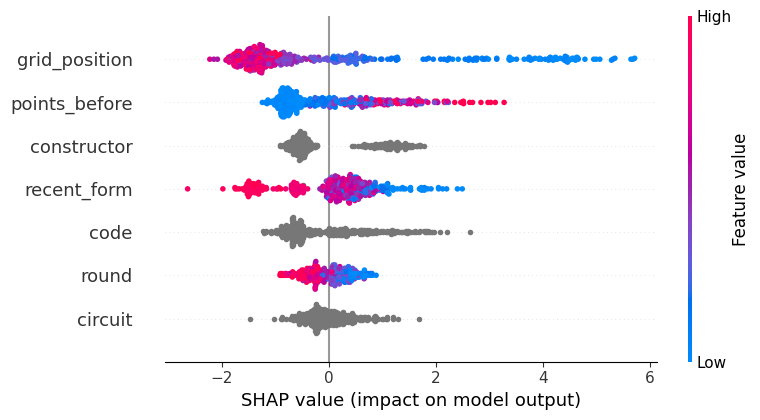

In [14]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    shap.summary_plot(shap_values, shap_holdout[BEST], show=False)
plt.tight_layout()
plt.show()

In [15]:
# This notebook's `constructor` column is the sponsor name. Notebook 03 maps names to
# constructor lineages; the race archive uses its own set of names, so the count here is
# its own. Test both labellings, because the choice changes the answer.
LINEAGE = {'Sauber': 'Hinwil', 'Alfa Romeo': 'Hinwil',
           'Force India': 'Silverstone', 'Racing Point': 'Silverstone',
           'Aston Martin': 'Silverstone', 'Toro Rosso': 'Faenza',
           'AlphaTauri': 'Faenza', 'RB F1 Team': 'Faenza',
           'Renault': 'Enstone', 'Alpine F1 Team': 'Enstone'}

unmapped = set(LINEAGE) - set(model_frame['constructor'].astype(str))
assert not unmapped, f'lineage keys that match nothing in the data: {sorted(unmapped)}'
model_frame['lineage'] = (model_frame['constructor'].astype(str)
                          .replace(LINEAGE).astype('category'))
POOLED = [c if c != 'constructor' else 'lineage' for c in BEST]
print(f"sponsor-name teams: {model_frame['constructor'].nunique()}  ->  "
      f"lineage constructors: {model_frame['lineage'].nunique()}")
print()


def mean_abs_shap(columns, fitted, holdout):
    model = LGBMClassifier(**BOOSTING)
    model.fit(fitted[columns], fitted['podium'])
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        values = shap.TreeExplainer(model).shap_values(holdout[columns])
    if isinstance(values, list):
        values = values[1]
    elif values.ndim == 3:
        values = values[:, :, 1]
    return pd.Series(np.abs(values).mean(axis=0), index=columns)


# Is constructor-above-driver a property of the model, or of one split and one labelling?
split_rows = []
for explain_season in [2021, 2022, 2023]:
    fitted = model_frame[model_frame['year'] < explain_season]
    holdout = model_frame[model_frame['year'] == explain_season]
    by_name = mean_abs_shap(BEST, fitted, holdout)
    by_lineage = mean_abs_shap(POOLED, fitted, holdout)
    split_rows.append({
        'explained': explain_season,
        'grid_position': by_name['grid_position'],
        'constructor': by_name['constructor'], 'driver': by_name['code'],
        'lineage_team': by_lineage['lineage'], 'lineage_driver': by_lineage['code'],
    })

across_splits = pd.DataFrame(split_rows).set_index('explained')
across_splits['car above driver'] = across_splits['constructor'] > across_splits['driver']
print('mean |SHAP| by which season is explained:')
print(across_splits.round(4).to_string())

sponsor-name teams: 16  ->  lineage constructors: 10

mean |SHAP| by which season is explained:
           grid_position  constructor  driver  lineage_team  lineage_driver  car above driver
explained                                                                                    
2021              1.8637       0.1167  0.8587        0.0429          0.8789             False
2022              1.8922       0.3995  0.7344        0.3068          0.7302             False
2023              1.5845       0.7234  0.6467        0.5541          0.6097              True


### Grid position dominates, and the labels underneath it barely register

| feature | mean \|SHAP\| |
|---|---|
| grid_position | **1.5845** |
| points_before | 0.7914 |
| **constructor** | **0.7234** |
| recent_form | 0.6685 |
| driver | 0.6467 |
| round | 0.3145 |
| circuit | 0.3043 |

These are log-odds contributions, so the ratios between them carry the meaning and the absolute
sizes do not.

**Starting position contributes twice as much as the next feature.** That is the sanity check
passing: the model found the real mechanism, not a shortcut.

**Constructor edges driver on this split, and that ordering means nothing.** The table explains
2023. Explaining an earlier season reverses it: 2021 gives 0.12 for constructor against 0.86 for
driver, and 2022 gives 0.40 against 0.73. Applying notebook 03's map of which team names are really
the same constructor, which collapses 16 names to 10, puts the driver first on all three seasons
including 2023. Two different changes, two different reversals.

**What does matter is how far below starting position both of them sit**, which the removal test
above showed directly: dropping constructor costs 0.0059 and dropping driver costs 0.0180, against a
noise floor of 0.063. **The grid slot already contains the car, and the driver.** Verstappen starts
on pole because the Red Bull is quick and because he put it there, and those two facts arrive fused
into a single number, leaving the labels very little to add.

**And that is the trap a predictive model sets.** It answers "who will finish on the podium?" while
being structurally incapable of answering "how much of this is the car?" The second question means
prising that fused number apart, which is what notebooks 01 to 03 did.

In [16]:
ratio = (~selection['podium']).sum() / selection['podium'].sum()
WEIGHTED = f'scale_pos_weight={ratio:.1f}'

imbalance = pd.DataFrame([
    evaluate(BEST, 'default')[0],
    evaluate(BEST, WEIGHTED, scale_pos_weight=ratio)[0],
    evaluate(BEST, 'class_weight=balanced', class_weight='balanced')[0],
]).set_index('features')[COLUMNS]

print(f'negative:positive across 2018-2023 = {ratio:.1f}:1')
print()
imbalance.round(4)

negative:positive across 2018-2023 = 5.7:1



,pr_auc,pr_auc_sd,log_loss,precision,recall
features,,,,,
default,0.6793,0.0630,0.3044,0.6406,0.5606
scale_pos_weight=5.7,0.6623,0.0709,0.3382,0.6252,0.6667
class_weight=balanced,0.6737,0.0759,0.3191,0.6127,0.6465


### Does telling the model to care more about podiums actually help?

Only 15% of entries reach the podium, and the standard response to a rare outcome is to reweight:
tell the model that missing a podium costs several times more than a false alarm, so it stops
playing safe.

**Reweighting scores worse on PR-AUC**, 0.6623 and 0.6737 for the two reweighted versions against
0.6793 for none, while recall rises and precision falls across the three.

That is the pattern you would see if reweighting were not improving the model's *ranking* of drivers
by how likely they are to reach the podium, and were only shifting the cut-off at which a predicted
probability gets called a podium. You can shift that cut-off afterwards, on a model you have already
fitted, for nothing.

**That is a hypothesis, not a finding.** If it is right, taking the plain model and lowering its
cut-off should reproduce the reweighted model's recall at equal or better precision. The sweep below
tests it with both sides pooled across the three validation seasons, so the two numbers compared are
the same kind of average.

In [17]:
# The table above averages three per-season scores. A threshold sweep runs on the
# three seasons pooled. Comparing one against the other compares two different kinds
# of average, so every configuration is pooled here instead.
pooled_rows = {}
for label, settings in [('default', {}),
                        (WEIGHTED, {'scale_pos_weight': ratio}),
                        ('class_weight=balanced', {'class_weight': 'balanced'})]:
    _, _, out_of_fold = evaluate(BEST, label, **settings)
    call = out_of_fold['probability'] >= 0.5
    pooled_rows[label] = {
        'precision': precision_score(out_of_fold['podium'], call, zero_division=0),
        'recall': recall_score(out_of_fold['podium'], call, zero_division=0),
    }
    if label == 'default':
        plain_out_of_fold = out_of_fold

pooled = pd.DataFrame(pooled_rows).T
target_recall = pooled.loc[WEIGHTED, 'recall']

sweep = []
for threshold in np.arange(0.05, 0.75, 0.01):
    prediction = plain_out_of_fold['probability'] >= threshold
    sweep.append({
        'threshold': threshold,
        'precision': precision_score(plain_out_of_fold['podium'], prediction, zero_division=0),
        'recall': recall_score(plain_out_of_fold['podium'], prediction, zero_division=0),
    })
sweep = pd.DataFrame(sweep)

matched = sweep.iloc[(sweep['recall'] - target_recall).abs().argmin()]
print(f'pooled out-of-fold predictions: {len(plain_out_of_fold)} rows across {VALIDATION_SEASONS}')
print()
print(pooled.round(4).to_string())
print()
print(f'reweighted model : recall {target_recall:.4f}, '
      f'precision {pooled.loc[WEIGHTED, "precision"]:.4f}')
print(f'plain + threshold: recall {matched["recall"]:.4f}, '
      f'precision {matched["precision"]:.4f}  (threshold {matched["threshold"]:.2f})')

pooled out-of-fold predictions: 1320 rows across [2021, 2022, 2023]

                       precision  recall
default                   0.6416  0.5606
scale_pos_weight=5.7      0.6256  0.6667
class_weight=balanced     0.6124  0.6465

reweighted model : recall 0.6667, precision 0.6256
plain + threshold: recall 0.6616, precision 0.6065  (threshold 0.31)


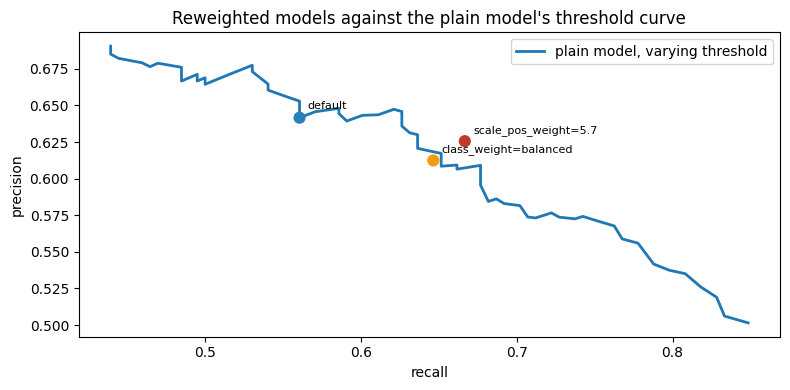

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep['recall'], sweep['precision'], lw=2, label='plain model, varying threshold')
ax.scatter(pooled['recall'], pooled['precision'], zorder=3, s=60,
           c=['#2980b9', '#c0392b', '#f39c12'])
for name, row in pooled.iterrows():
    ax.annotate(name, (row['recall'], row['precision']),
                textcoords='offset points', xytext=(6, 6), fontsize=8)
ax.set_xlabel('recall')
ax.set_ylabel('precision')
ax.set_title('Reweighted models against the plain model\'s threshold curve')
ax.legend()
plt.tight_layout()
plt.show()

### Reweighting does buy something, and it is not what the ranking says

| pooled across 2021-2023 | precision | recall |
|---|---|---|
| plain model at 0.5 | 0.6416 | 0.5606 |
| reweighted, `scale_pos_weight=5.7` | 0.6256 | **0.6667** |
| plain model at threshold 0.31 | 0.6065 | 0.6616 |

**The hypothesis fails.** Lowering the plain model's cut-off to 0.31 reaches almost the same recall
as reweighting, 0.6616 against 0.6667, but at **worse** precision, 0.6065 against 0.6256.
Reweighting holds about 1.9 points more precision at that operating point, so it is doing something
a threshold move does not reproduce.

**The two measures disagree, and both are right.** Reweighting produces a worse ranking overall,
0.6623 PR-AUC against 0.6793, and a better trade at the high-recall end. Both hold: PR-AUC averages
across every cut-off, and most cut-offs are ones nobody would use.

**Decision: no reweighting**, on the rule set at the start, which chooses on the headline measure.
The honest caveat is that the rule is doing the deciding here. If the goal were catching as many
podiums as possible rather than ranking them, the reweighted model is the better tool, and 1.9
points is a real difference at a single operating point even if it is inside the fold-to-fold noise.

**Worth flagging: an earlier version of this section reached the opposite conclusion**, that the
plain model matched reweighting at better precision. It read the reweighted model's precision off
the fold-averaged table and the plain model's off the pooled sweep. Recall survives that mix
unharmed, since each season carries the same 66 podiums and averaging equals pooling, which is why
the recalls above are identical in both tables. Precision does not: each fold has its own number of
podium calls, so averaging three fold precisions is not the precision of the three pooled together.
Reading both sides the same way reversed the answer.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_logistic(numeric_columns):
    return Pipeline([
        ('prepare', ColumnTransformer([
            ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
                                  ('scale', StandardScaler())]), numeric_columns),
            ('categorical', OneHotEncoder(handle_unknown='ignore'), CATEGORICAL),
        ])),
        ('model', LogisticRegression(max_iter=2000, random_state=0)),
    ])


NUMERIC = [c for c in BEST if c not in CATEGORICAL]

boosting_folds, _ = cross_validate(BEST, lambda: LGBMClassifier(**BOOSTING))
linear_folds, linear_out_of_fold = cross_validate(BEST, lambda: build_logistic(NUMERIC))

comparison = pd.DataFrame([
    {'model': 'LightGBM', **boosting_folds.mean().to_dict(),
     'pr_auc_sd': boosting_folds['pr_auc'].std()},
    {'model': 'logistic regression', **linear_folds.mean().to_dict(),
     'pr_auc_sd': linear_folds['pr_auc'].std()},
]).set_index('model')[COLUMNS]

print('per-fold PR-AUC:')
print(pd.DataFrame({'LightGBM': boosting_folds['pr_auc'],
                    'logistic': linear_folds['pr_auc']}).round(4).to_string())
print()
comparison.round(4)

per-fold PR-AUC:
      LightGBM  logistic
fold                    
2021    0.7515    0.7499
2022    0.6503    0.6924
2023    0.6360    0.6825



,pr_auc,pr_auc_sd,log_loss,precision,recall
model,,,,,
LightGBM,0.6793,0.0630,0.3044,0.6406,0.5606
logistic regression,0.7083,0.0364,0.2303,0.7182,0.5051


### Logistic regression wins the comparison

| cross-validated | PR-AUC | spread | log-loss | precision | recall |
|---|---|---|---|---|---|
| LightGBM | 0.6793 | 0.063 | 0.3044 | 0.6406 | 0.5606 |
| **logistic regression** | **0.7083** | **0.036** | **0.2303** | **0.7182** | 0.5051 |

| per-fold PR-AUC | 2021 | 2022 | 2023 |
|---|---|---|---|
| LightGBM | 0.7515 | 0.6503 | 0.6360 |
| logistic regression | 0.7499 | 0.6924 | 0.6825 |

Logistic regression is the plain alternative to gradient boosting: it weights each feature, adds the
weighted values up, and turns the total into a probability. No trees, no combinations.

**It is level in 2021 and ahead in 2022 and 2023**, varies less between seasons, and has a much
lower log-loss. That matters to anyone who wants to read "0.7" as a genuine 70% chance rather than
as a score.

**The result follows from what SHAP showed.** Starting position carries most of the information, and
it works in one direction: the further forward you start, the further forward you finish. There is
little curvature and few combinations left for a tree model to find, so it finds little, and pays
for the search with noisier estimates.

Two things keep this from being a verdict on the model families. LightGBM runs on its defaults, by
the choice made at the top of this notebook, so what lost here is untuned gradient boosting on 2,500
rows. And the logistic pipeline fills missing `recent_form` values with the median while LightGBM
handles them natively, so the two are not fed quite identical data.

**Running the simple model is still what tells you whether the complicated one is earning its
place.** Here it is not, and the rule set at the start is to take whichever model the three
validation seasons preferred, so logistic regression becomes the baseline.

## The final model, evaluated once

**Every model score so far came from the 2021, 2022 and 2023 validation seasons, and every choice in this notebook was made by comparing those numbers**: which features to keep, how to define `recent_form`, whether to reweight, which model family.

One exception, stated because the discipline is the point of this section: the correlation and Cramer's V tables in cell 16, the first pass at feature selection, are computed on the whole span rather than on the validation seasons alone. No cell here recomputes them, so how much they would move is not shown. They are not clean, and the sentence above would be wrong without this note.

Those three seasons are now used up. Any score on them is flattering by construction, because the winner of each comparison was picked for scoring well on that data.

**2024 and 2025 have not been touched.** The chosen setup is refitted on everything up to and including 2023, then run against those two seasons once. That is the number worth quoting.

Both models are reported, not just the winner, because seeing whether the validation result held up is more informative than seeing the winner alone.

In [20]:
final_train = model_frame[model_frame['year'] <= 2023]

final_lightgbm = LGBMClassifier(**BOOSTING)
final_lightgbm.fit(final_train[BEST], final_train['podium'])

final_logistic = build_logistic(NUMERIC)
final_logistic.fit(final_train[BEST], final_train['podium'])

front_three = test['grid_position'] <= 3

final = pd.DataFrame([
    score(final_lightgbm, test, BEST, 'LightGBM'),
    score(final_logistic, test, BEST, 'logistic regression'),
    {'fold': 'grid slot only, no model',
     'pr_auc': grid_only_pr_auc(test),
     'log_loss': float('nan'),
     'precision': precision_score(test['podium'], front_three, zero_division=0),
     'recall': recall_score(test['podium'], front_three, zero_division=0)},
]).set_index('fold')

# The notebook argued for moving the cut-off rather than reweighting, so the chosen model
# is also read there. Its cut-off is found on its own out-of-fold probabilities: the two
# model families are calibrated differently, so a threshold does not transfer between them.
linear_sweep = pd.DataFrame([
    {'threshold': threshold,
     'recall': recall_score(linear_out_of_fold['podium'],
                            linear_out_of_fold['probability'] >= threshold, zero_division=0),
     'precision': precision_score(linear_out_of_fold['podium'],
                                  linear_out_of_fold['probability'] >= threshold, zero_division=0)}
    for threshold in np.arange(0.05, 0.75, 0.01)])
linear_matched = linear_sweep.iloc[(linear_sweep['recall'] - target_recall).abs().argmin()]
chosen_threshold = float(linear_matched['threshold'])
at_threshold = final_logistic.predict_proba(test[BEST])[:, 1] >= chosen_threshold

print(f'refitted on {len(final_train)} rows (2018-2023), '
      f'evaluated on {len(test)} rows (2024-2025)')
print()
print('cross-validated across 2021-2023, used for every decision:')
print(comparison.round(4).to_string())
print()
print('test (2024-2025), touched once:')
print(final.round(4).to_string())
print()
print(f'boosting cut-off {matched["threshold"]:.2f} matched recall {target_recall:.4f}; '
      f'the same recall on logistic needs {chosen_threshold:.2f}')
print(f'logistic regression at its own cut-off {chosen_threshold:.2f}: '
      f'precision {precision_score(test["podium"], at_threshold, zero_division=0):.4f}, '
      f'recall {recall_score(test["podium"], at_threshold, zero_division=0):.4f}')

refitted on 2500 rows (2018-2023), evaluated on 938 rows (2024-2025)

cross-validated across 2021-2023, used for every decision:
                     pr_auc  pr_auc_sd  log_loss  precision  recall
model                                                              
LightGBM             0.6793     0.0630    0.3044     0.6406  0.5606
logistic regression  0.7083     0.0364    0.2303     0.7182  0.5051

test (2024-2025), touched once:
                          pr_auc  log_loss  precision  recall
fold                                                         
LightGBM                  0.6505    0.2769     0.6202  0.5674
logistic regression       0.6488    0.2378     0.6822  0.5177
grid slot only, no model  0.6977       NaN     0.7092  0.7092

boosting cut-off 0.31 matched recall 0.6667; the same recall on logistic needs 0.38
logistic regression at its own cut-off 0.38: precision 0.6145, recall 0.7234


### Both models lost ground, and both lost to the grid

| | cross-validated | test | change |
|---|---|---|---|
| LightGBM | 0.6793 | 0.6505 | -0.029 |
| logistic regression | 0.7083 | 0.6488 | **-0.059** |
| **rank by grid slot, no model** | 0.6460 | **0.6977** | +0.052 |

**The reference beats both models on the seasons nobody selected on.** Sorting the field by starting
slot scores 0.6977 against 0.6488 for the model this notebook chose. Worse, the two-line rule "the
front three on the grid are your podium" gets precision 0.7092 and recall 0.7092, against the chosen
model's 0.6822 and 0.5177. It wins on both at once. Those two numbers are identical by construction
rather than luck: the rule names exactly three drivers a race and exactly three finish on the
podium, so every miss costs precision and recall equally.

**On the validation seasons the models did beat the grid**, 0.7083 and 0.6793 against 0.6460. So the
whole measured benefit of the modelling is the part that failed to survive data nobody had selected
on.

**Two separate things produce that reversal, and only one of them is selection.** The models fell,
0.029 and 0.059, which is the price of having chosen them on those seasons. But the grid reference
**rose** 0.052 on the same data, and no amount of selection cost can lift a rule that was never
fitted to anything. 2024 and 2025 were simply more decided by the starting order than 2021 to 2023
were. The models' drop is selection; the reference's rise is the seasons.

**Neither model held its validation score, and the one that was chosen dropped furthest**, 0.059
against 0.029. Both validation scores came from the three seasons every choice was made on, so both
were flattering by construction.

Logistic regression stays as the baseline. The rule set at the start was to choose on the validation
seasons and report on the held-out ones; switching now would undo the discipline the structure
exists to enforce. But the honest headline is not which model won. It is that **neither of them
earned its place against the starting grid.**

On log-loss the model still has something the grid rule cannot offer: 0.2378 against 0.2769 for
LightGBM, and a bare ranking by grid slot has no calibrated probability at all. If what you want is
a number you can read as a chance, the model gives you one. If what you want is the podium, the grid
gives it to you for free.

One operating-point note. The reweighting section found its cut-off on the boosting model, and a
threshold does not carry across model families: the two are calibrated differently, so reaching the
same recall takes 0.31 there and **0.38** here. Read at its own 0.38, the chosen model gives
precision 0.6145 and recall 0.7234 on the held-out seasons. That is a far better trade than the 0.5
default in the table above, and it still does not beat the grid rule's 0.7092 and 0.7092.

## Saving the baseline

In [21]:
import json as json_module
import pickle
from pathlib import Path

output_dir = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('.')

# the folds chose the model, so the saved baseline follows them rather than the test scores
chosen = comparison['pr_auc'].idxmax()
baseline_model = {'LightGBM': final_lightgbm, 'logistic regression': final_logistic}[chosen]

with open(output_dir / 'baseline_model.pkl', 'wb') as handle:
    pickle.dump(baseline_model, handle)

baseline_metrics = {
    'chosen_model': chosen,
    'features': BEST,
    'validation': 'expanding window, folds validated on 2021, 2022, 2023',
    'refit_season_range': {'first': 2018, 'last': 2023},
    'test_seasons': [2024, 2025],
    'podium_rate': float(features['podium'].mean()),
    'cross_validated': {name: {k: float(v) for k, v in row.items()}
                        for name, row in comparison.iterrows()},
    'test': {name: {k: (None if pd.isna(v) else float(v)) for k, v in row.items()}
             for name, row in final.iterrows()},
}
with open(output_dir / 'baseline_metrics.json', 'w') as handle:
    json_module.dump(baseline_metrics, handle, indent=2)

print('saved baseline:', chosen)
print(json_module.dumps(baseline_metrics, indent=2))

saved baseline: logistic regression
{
  "chosen_model": "logistic regression",
  "features": [
    "grid_position",
    "round",
    "code",
    "constructor",
    "circuit",
    "points_before",
    "recent_form"
  ],
  "validation": "expanding window, folds validated on 2021, 2022, 2023",
  "refit_season_range": {
    "first": 2018,
    "last": 2023
  },
  "test_seasons": [
    2024,
    2025
  ],
  "podium_rate": 0.15008726003490402,
  "cross_validated": {
    "LightGBM": {
      "pr_auc": 0.6792632799667245,
      "pr_auc_sd": 0.06295462343865989,
      "log_loss": 0.304389779832941,
      "precision": 0.640583373604451,
      "recall": 0.5606060606060606
    },
    "logistic regression": {
      "pr_auc": 0.7082707987879558,
      "pr_auc_sd": 0.036425787078925784,
      "log_loss": 0.23032641918112196,
      "precision": 0.7182098765432099,
      "recall": 0.5050505050505051
    }
  },
  "test": {
    "LightGBM": {
      "pr_auc": 0.6505407636595294,
      "log_loss": 0.276882637

## What this notebook establishes

**The finding is negative, and it is the most useful thing here.** On two seasons kept out of every
decision, a conventional pipeline of seven features and two model families does not beat ranking the
field by starting slot: 0.6488 against 0.6977, and the two-line "front three" rule beats the model
on precision and recall at once. On the three seasons used for selection, the models did win. Most
of that gap is selection and not all of it: the models fell 0.029 and 0.059, the price of having
been chosen on those seasons, but the grid reference *rose* 0.052 on data it was never fitted to, so
2024 and 2025 were also simply more decided by the starting order.

**That is the thesis, arriving from the other direction.** Where a car starts contributes twice as
much as anything else, and dropping the constructor and driver columns costs 0.0059 and 0.0180
against a noise floor of 0.063, because the grid slot already contains both fused into a single
number. A model built to predict results can be accurate and structurally unable to say how much of
a result is the driver. That is why notebooks 01 to 03 work on qualifying pace instead.

**Two pieces of method that changed an answer**, both about class reweighting. Validating on three
seasons instead of one reversed it once, with no code changed. Reading both sides of the precision
comparison the same way, pooled rather than one pooled and one fold-averaged, reversed it again.

**What it does not establish.** Every feature comparison sits inside the fold-to-fold noise, so they
are leans rather than results. Untuned gradient boosting lost to logistic regression here, which is
not a verdict on the families. And no tuning, calibration curve or richer feature set was tried, any
of which might close the gap to the grid rule.